# Discrepancy-01 - Beck-Fiala (la noix `disc <= 2k-1`) et le pont vers le lake `discrepancy_lean`

> **Premier carnet de la sous-série `Discrepancy/`.** Il expose en Python les énoncés du lake `discrepancy_lean` (Mathlib4 pinné `db584cd6`, toolchain `leanprover/lean4:v4.33.0` dans `discrepancy_lean/lean-toolchain`) et rend palpable la frontière entre ce qui est **certifié** sur `main` et ce qui ne l'est pas : une conjecture n'est jamais présentée comme un résultat. Ce notebook n'est pas une preuve formelle : il implémente un **squelette** de l'algorithme de Beck-Fiala (rounding itératif, départ `0`, phases sur les lignes dangereuses), expose les définitions Lean verbatim comme citations, et compare la discrépance obtenue à la borne `2k - 1` du théorème `beck_fiala_classic`.

> **Précondition du théorème.** La borne `2*k - 1` de `beck_fiala_classic` n'engage que sous la précondition `maxDegree(F) ≤ k`, où `k` borne le **degré** maximal d'un sommet, et non la cardinalité des parties. Sur les instances aléatoires de la cellule 4 (`n=10, m=15, k_max=2`), cette précondition est violée pour les 40 instances (degré maximal mesuré entre 4 et 9) : la borne n'est donc pas applicable, et les cellules 3 et 5 en tirent les conséquences.

**Navigation** : [Search README](..) ; [LEAN_INVENTORY](../LEAN_INVENTORY.md) ; [FORMAL_STATUS](../discrepancy_lean/FORMAL_STATUS.md) ; module source [BeckFiala.lean](../discrepancy_lean/Discrepancy/BeckFiala.lean). Issue de suivi : #17816.


## 0. Setup et hommage

Ce notebook depend de la bibliotheque standard Python et de `matplotlib` (les trois figures de la cellule 6). Il ne depend **pas** de Lean au runtime. Les noms Lean apparaissent **uniquement comme chaînes verbatim** dans les docstrings (namespace **plat** `Discrepancy.*`, tel qu'ouvre `Basic.lean` l.38 et ferme `BeckFiala.lean` au-delà de la ligne `320`) :

- `Discrepancy.IsColoring` : `def IsColoring (c : \u03b1 -> Int) : Prop := fun x => c x = 1 \/ c x = -1` (`Basic.lean` l.44)
- `Discrepancy.discrepancy` : `def discrepancy (F c) : Nat := (F.image (fun S => (S.sum c).natAbs)).sup id` (`Basic.lean` l.50)
- `Discrepancy.degree` : `degree F x = (F.filter (fun S => x in S)).card` (`Basic.lean` l.56)
- `Discrepancy.maxDegree` : `Finset.univ.sup (fun x => degree F x)` (`Basic.lean` l.61)
- `Discrepancy.BeckFialaClassic` (la noix) - **signature verbatim** `Basic.lean:118-120` :
  ```
  def BeckFialaClassic : Prop :=
    ∀ (n k : ℕ) (F : Finset (Finset (Fin n))) (_hk : maxDegree F ≤ k) (_hk1 : 1 ≤ k),
      ∃ c : Fin n → ℤ, IsColoring c ∧ (discrepancy F c : ℤ) ≤ 2 * (k : ℤ) - 1
  ```
- Note sur la **lecture** de cette signature : le théorème prend `k` comme borne sur `maxDegree(F)`, PAS comme borne sur la cardinalité d'une partie. Dans la cellule 4, `k_max` borne la cardinalité (tirage `rng.randint(1, min(k_max+2, n))`), ce qui viole généralement la precondition `maxDegree(F) ≤ k_max`.
- `Discrepancy.BFInv` : invariant `BFInv F k X c` (`BeckFiala.lean` l.45, **def**)
- `Discrepancy.beck_fiala_classic` : `theorem beck_fiala_classic : BeckFialaClassic` (`BeckFiala.lean` l.283, **PROUVE sur main**)

Le module `BeckFiala.lean` déclare les théorèmes publics `exists_phase`, `exists_coloring_of_no_danger`, `bf_loop`, `beck_fiala_classic` et la définition `BFInv` (positions verbatim dans le tableau de l'exercice 3). Le statut `sorry` se vérifie avec `python scripts/lean/count_code_sorry.py --json`, instrument qui compte les `sorry` de code et non ceux de la prose.

**Avertissement de portage** : le `rounding_pass` ci-dessous est un **squelette pedagogique** : la direction `v` choisie est triviale (`+1` sur un seul flottant pivot), ce qui ne preserve **pas** les sommes sur les lignes dangereuses. Le lean `exists_phase` exige une direction dans le **noyau** des contraintes ; cela correspond a l'Exercice 1 ci-dessous. La comparaison avec random search best-of-50 (cellule 4) reflete donc cette limite - c'est l'intention pedagogique.


In [1]:
# Implementation Python du squelette algorithmique de Beck-Fiala (rounding iteratif).
# Conventions : `set_family` = liste de `frozenset` ; chaque `S in F` est une partie finie.
# L'algorithme part d'une coloration identiquement nulle (tout flottant), repere les lignes
# dangereuses (celles ayant strictement plus de `k` flottants), choisit une direction dans le
# noyau `Q^X -> Q^D` (b1 cite `exists_dangerous_kernel_vec`), avance tant qu'un flottant atteint
# `|c[x]| = 1` (b3), puis fige : `c[x] = 1` ou `-1` selon le signe (invariant `frozen_line_sum_le`
# de b2). Squelette ici : la direction est une simplification `+1` sur un flottant pivot - elle
# ne preserve pas la somme des lignes dangereuses (cf. Exercice 1 pour la version correcte).

import itertools
import random
from typing import Dict, FrozenSet, List, Sequence, Tuple


def max_degree(F: Sequence[FrozenSet[int]]) -> int:
    """`maxDegree F = univ.sup (fun x => degree F x)` (Lean `Discrepancy.maxDegree`).
    Renvoie le degré maximal d'une famille : le `k` des enonces Beck-Fiala.
    """
    if not F:
        return 0
    universe = set().union(*F)
    return max(sum(1 for S in F if x in S) for x in universe)


def discrepancy_int(F: Sequence[FrozenSet[int]], c: Dict[int, int]) -> int:
    """`discrepancy F c = (F.image (fun S => (S.sum c).natAbs)).sup id` (Lean `Discrepancy.discrepancy`).
    Discrepance entiere : max des valeurs absolues des sommes signees sur la famille.
    """
    if not F:
        return 0
    return max(abs(sum(c[x] for x in S)) for S in F)


def rounding_pass(F: Sequence[FrozenSet[int]], k: int, c: Dict[int, float],
                  X: set, danger: Sequence[FrozenSet[int]], verbose: bool = False
                  ) -> Tuple[Dict[int, float], set, List[FrozenSet[int]], bool]:
    """Une phase du squelette de Beck-Fiala (cf. `exists_phase` `BeckFiala.lean` l.80).
    Version simplifiee : direction `+1` sur un flottant pivot seulement. Cf. Exercice 1
    pour la version qui prend un vecteur dans le noyau des lignes dangereuses.
    """
    if not X or not danger:
        return c, X, [], False
    S_danger = max(danger, key=lambda S: len(S & X))
    pivot = next(iter(S_danger & X))
    max_step = min(1.0 - abs(c[pivot]), max(1.0 - abs(c[x]) for x in S_danger & X))
    if max_step <= 0:
        return c, X, [S for S in danger if S & X and len(S & X) > k], False
    step = random.uniform(0.0, max_step)
    new_c = {x: c[x] for x in c}
    new_c[pivot] = c[pivot] + step
    new_X = {x for x in X if abs(new_c[x]) < 1.0}
    fixed = X - new_X
    for x in fixed:
        new_c[x] = 1.0 if new_c[x] >= 0 else -1.0
    progress = len(fixed) >= 1
    if verbose:
        print(f"    [phase] pivot={pivot} step={step:.3f} |X|={len(X)} -> {len(new_X)}, fixed={len(fixed)}")
    return new_c, new_X, [S for S in danger if S & new_X and len(S & new_X) > k], progress


def beck_fiala(F: Sequence[FrozenSet[int]], k: int, max_iter: int = 100,
               verbose: bool = False) -> Tuple[Dict[int, int], List[int]]:
    """Algorithme de Beck-Fiala (rounding iteratif), portage simplifie du squelette Lean.
    Renvoie `(coloring, history)` ou `coloring` est une coloration `+/-1` et `history` est la
    suite du nombre de flottants après chaque phase.
    """
    universe = set().union(*F) if F else set()
    if not universe:
        return {}, []
    c = {x: 0.0 for x in universe}
    X = set(universe)
    history = [len(X)]
    for it in range(max_iter):
        danger = [S for S in F if len(S & X) > k]
        if not danger:
            if verbose:
                print(f"  [iter {it}] plus de ligne dangereuse, arret |X|={len(X)}")
            break
        c, X, danger, progress = rounding_pass(F, k, c, X, danger, verbose=verbose)
        history.append(len(X))
        if not progress or not X:
            break
    return {x: (1 if c[x] >= 0 else -1) for x in universe}, history


# --- Demonstration : toutes les 3-parties de [n=6] sont des lignes dangereuses (`|S|=3 > k=2`). ---
random.seed(7)
n6 = 6
triples_6 = [frozenset(t) for t in itertools.combinations(range(n6), 3)]
k6 = 2
print(f"Famille : toutes les 3-parties de [n=6] -> |F|={len(triples_6)} ; k={k6} ; borne 2k-1={2*k6-1}")
print(f"maxDegree = {max_degree(triples_6)} ; chaque ligne est dangereuse : |S|={3} > k={k6}")
coloring6, history6 = beck_fiala(triples_6, k6, verbose=True)
print(f"Histoire des flottants : {history6}")
print(f"Coloration finale : {coloring6}")
print(f"Discrepance obtenue : {discrepancy_int(triples_6, coloring6)}")
print(f"Borne 2k-1 annoncee par `beck_fiala_classic` : {2*k6-1}")

Famille : toutes les 3-parties de [n=6] -> |F|=20 ; k=2 ; borne 2k-1=3
maxDegree = 10 ; chaque ligne est dangereuse : |S|=3 > k=2
    [phase] pivot=0 step=0.324 |X|=6 -> 6, fixed=0
Histoire des flottants : [6, 6]
Coloration finale : {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
Discrepance obtenue : 3
Borne 2k-1 annoncee par `beck_fiala_classic` : 3


### Lecture du résultat (cellule 2)

Sur la famille `F = { tous les triplets de [n=6] }`, chaque partie est de cardinalité `|S| = 3`. Le `k` du paramètre Beck-Fiala serait le **degré** `maxDegree(F)`, mais ici `maxDegree(F) = 10` (chaque sommet de [n=6] apparait dans `C(5,2) = 10` triplets), donc `k = 10`, **PAS** `k = 2`. La cellule 2 imprime d'ailleurs `maxDegree = 10`. La borne `2k - 1 = 3` qu'elle affiche suppose `maxDegree(F) ≤ 2`, précondition fausse ici : sa coïncidence avec la discrépance observée (3) ne prouve rien.

Notre **squelette** utilise une direction triviale (`+1` sur un flottant pivot), ce qui **ne preserve pas** la somme sur les lignes dangereuses. Une vraie implementation doit prendre un vecteur dans le noyau `Q^X -> Q^D` (Exercice 1 ci-dessous). La discrépance observee sur cette famille est `3 = cardinalité(S)` (toutes les parties somment a `+3` car tous les sommets finissent a `+1`) : **egalite numérique avec `2*k-1` ne valide rien**, et la comparer a la borne du théorème est trompeur.

**Sans kernel direction**, l'algorithme n'a aucune raison de battre la borne, et c'est la qu'Exercice 1 ferme la lacune. Le test quantitatif est en cellule 4, ou la comparaison se fait entre BF-squelette et random best-50 (la borne du théorème n'etant pas applicable a ces instances).


In [2]:
import statistics


def random_hypergraph(n: int, m: int, k_max: int, seed: int) -> List[FrozenSet[int]]:
    """Hypergraphe aléatoire : `m` parties aléatoires parmi `n` sommets.

    Borne de tirage : chaque partie a une cardinalite tiree UNIFORMEMENT dans `{1, ..., min(k_max+2, n)}` (le `+2` dans `k_max+2` reflete le fait que `random.randint(a, b)` inclut les bornes ; la borne SUPERIEURE effective du tirage est donc `min(k_max+2, n)`, pas `k_max` directement). `k_max` borne donc la cardinalite **maximale théorique du tirage** (= `k_max+2`), PAS un maximum exact, et surtout PAS le `maxDegree(F)` du theoreme Beck-Fiala.

    Terminologie : sur n=10, m=15, k_max=2, chaque sommet apparait en moyenne dans m * cardinalite_moyenne / n = 15 * 2.5 / 10 = 3.75 parties (cardinalite_moyenne = (k_max+2+1)/2 = 2.5 pour k_max=2) ; le degré maximal mesuré se situe entre 4 et 9 (cf. sortie). La precondition `maxDegree(F) <= k_max` du theoreme est donc violee par construction : ces instances servent a comparer BF-squelette contre random best-50 la ou la borne `2*k-1` ne s'applique pas.
    """
    rng = random.Random(seed)
    F: List[FrozenSet[int]] = []
    for _ in range(m):
        size = rng.randint(1, min(k_max + 2, n))
        vertices = rng.sample(range(n), size)
        F.append(frozenset(vertices))
    return F


def random_coloring(n: int, rng: random.Random) -> Dict[int, int]:
    return {x: rng.choice((-1, 1)) for x in range(n)}


def empirical_test(n: int, m: int, k_max: int, n_instances: int = 40, n_restarts: int = 50):
    """Test experimental : comparaison BF-squelette vs random best-of-N restarts.

    Pour chaque instance, on tire (a) la coloration par notre squelette BF, et (b) le
    meilleur de `n_restarts` colorations aléatoires. On agrege les discrepances.

    On mesure aussi `maxDegree(F)` par instance :
    la borne `2*k - 1` du theoreme `beck_fiala_classic` n'engage que sous la
    précondition `maxDegree(F) <= k`. Hors de cette précondition, comparer la
    discrepance observee a `2*k - 1` ne prouve rien. On rapporte donc les
    DEUX grandeurs : `2*k_max - 1` (borne NAIVE, non applicable) et la borne
    effective `2*maxDegree(F) - 1` instance par instance.
    """
    bf_discs: List[int] = []
    rnd_discs: List[int] = []
    bf_history_lengths: List[int] = []
    max_degrees: List[int] = []
    for i in range(n_instances):
        F = random_hypergraph(n, m, k_max, seed=1000 + i)
        coloring, history = beck_fiala(F, k_max)
        bf_discs.append(discrepancy_int(F, coloring))
        bf_history_lengths.append(len(history))
        max_degrees.append(max_degree(F))
        rng = random.Random(2000 + i)
        best_random = min(
            discrepancy_int(F, random_coloring(n, rng))
            for _ in range(n_restarts)
        )
        rnd_discs.append(best_random)
    return bf_discs, rnd_discs, bf_history_lengths, max_degrees


# --- Test : hypergraphes `n=10`, `m=15`, `k_max=2`, 40 instances, 50 restarts random. ---
bf_discs, rnd_discs, lengths, max_degrees = empirical_test(
    n=10, m=15, k_max=2, n_instances=40, n_restarts=50
)
kmax = 2
print(f"Hypergraphes aléatoires `n={10}`, `m={15}`, `k_max={kmax}`, 40 instances :")
print(f"maxDegree(F) mesure par instance : min={min(max_degrees)} mean={statistics.mean(max_degrees):.2f} max={max(max_degrees)}")
print(f"Precondition Beck-Fiala `maxDegree <= k_max` satisfaite : {sum(1 for d in max_degrees if d <= kmax)} / {len(max_degrees)} instances")
print(f"Discrepance BF-squelette : min={min(bf_discs)} mean={statistics.mean(bf_discs):.2f} max={max(bf_discs)}")
print(f"Discrepance random best-50 : min={min(rnd_discs)} mean={statistics.mean(rnd_discs):.2f} max={max(rnd_discs)}")
print(f"Phases du squelette : min={min(lengths)} mean={statistics.mean(lengths):.2f} max={max(lengths)}")
print(f"Borne naive 2*k_max - 1 = {2*kmax-1} (NON APPLICABLE : precondition `maxDegree <= k_max` violee 40/40)")
print(f"Borne effective 2*maxDegree - 1 par instance : min={min(2*d-1 for d in max_degrees)} mean={statistics.mean(2*d-1 for d in max_degrees):.2f} max={max(2*d-1 for d in max_degrees)}")
print(f"Rapport BF / random : mean(BF) / mean(rnd) = {statistics.mean(bf_discs) / statistics.mean(rnd_discs):.3f}")
print("Lectures :")
print(f"  - La borne du theoreme `beck_fiala_classic` (`2*k-1`) ne s'applique PAS a ces instances :")
print(f"    la precondition `maxDegree(F) <= k_max = 2` est violee sur 40/40 hypergraphes")
print(f"    (maxDegree reel entre {min(max_degrees)} et {max(max_degrees)}).")
print(f"  - La comparaison PERTINENTE est BF-squelette vs random best-50, point.")
print(f"    BF min={min(bf_discs)} > random max={max(rnd_discs)} sur 40/40 instances : le squelette")
print(f"    perd systematiquement, ce qui valide l'avertissement de portage (direction pivot")
print(f"    triviale qui ne preserve pas la somme sur les lignes dangereuses).")
print(f"  - Une vraie implementation avec `random_kernel_vector` (Exercice 1) doit fermer cet ecart.")
print(f"  - Les bornes plus serrees (Banaszczyk 1998, Bansal-Jiang 2025 `O(sqrt(k))` dans")
print(f"    `BansalJiangLargeDegree`) ne sont pas démontrées dans le lake de ce carnet.")


Hypergraphes aléatoires `n=10`, `m=15`, `k_max=2`, 40 instances :
maxDegree(F) mesure par instance : min=4 mean=6.65 max=9
Precondition Beck-Fiala `maxDegree <= k_max` satisfaite : 0 / 40 instances
Discrepance BF-squelette : min=4 mean=4.00 max=4
Discrepance random best-50 : min=1 mean=1.90 max=2
Phases du squelette : min=2 mean=2.00 max=2
Borne naive 2*k_max - 1 = 3 (NON APPLICABLE : precondition `maxDegree <= k_max` violee 40/40)
Borne effective 2*maxDegree - 1 par instance : min=7 mean=12.30 max=17
Rapport BF / random : mean(BF) / mean(rnd) = 2.105
Lectures :
  - La borne du theoreme `beck_fiala_classic` (`2*k-1`) ne s'applique PAS a ces instances :
    la precondition `maxDegree(F) <= k_max = 2` est violee sur 40/40 hypergraphes
    (maxDegree reel entre 4 et 9).
  - La comparaison PERTINENTE est BF-squelette vs random best-50, point.
    BF min=4 > random max=2 sur 40/40 instances : le squelette
    perd systematiquement, ce qui valide l'avertissement de portage (direction pivot
 

### Lecture du résultat (cellule 4)

La comparaison **squelette BF** vs **random search best-of-50** sur 40 hypergraphes aléatoires de paramètre `k_max = 2` (paramètre de TIRAGE : cardinalité des parties tiree uniformement dans `{1, ..., k_max+2=4}` - PAS le `maxDegree(F)` du théorème) donne **toujours un avantage au random search avec restarts**, parce que le squelette ne choisit pas la bonne direction dans la phase. Le squelette perd donc contre la recherche aléatoire : la cellule isole le défaut que l'Exercice 1 corrige, à savoir une direction qui ne reste pas dans le noyau des lignes dangereuses.

**Terminologie.** Dans cette expérience, `k_max` borne la cardinalité **tirée** de chaque partie : sa taille `|S|` est dans `{1, ..., k_max+2}` (= 4 au plus pour k_max=2). Ce n'est pas le `maxDegree(F)` du théorème Beck-Fiala. Le théorème `beck_fiala_classic` exige `maxDegree(F) <= k` et garantit `discrepancy <= 2*k - 1` ; la borne **2*k_max - 1 = 3** n'a donc aucune validité sur ces instances, et la comparer à la discrépance `BF = 4` ne dit rien. Les grandeurs mesurées sont :

1. **`maxDegree(F)` par instance** : la mesure brute du degré reel des 40 hypergraphes. Résultat : `min = 4, mean = 6.65, max = 9` (les valeurs exactes sont dans la sortie de la cellule 4). La precondition `maxDegree(F) <= k_max = 2` est violee sur **40/40** instances.

2. **BF-squelette vs random best-50** : la comparaison directe (random avec **50 restarts**, le minimum competitif) **favorise random**. Mesure : `mean(BF) = 4.00 > mean(rnd) = 1.90` (rapport 2.105). Sur 40/40 instances, `BF min = 4 > random max = 2` : le squelette perd systematiquement. Une vraie implementation avec `random_kernel_vector` doit fermer cet ecart.

3. **Terminaison `bf_loop`** : la trace de `history` ne montre **aucune décroissance** — la mesure de la cellule 6 donne, sur l'instance E7, `flottants = [10, 10]` et `figes = [0, 0]`. Le `2.00` de la cellule 4 est le nombre **moyen de phases** (deux entrées par instance), pas un nombre de flottants : la boucle s'arrête dès la première phase par `not progress`, parce que `rounding_pass` tire son pas dans `random.uniform(0.0, max_step)` avec `max_step = 1.0`, et qu'un pas strictement inférieur à 1 ne fait atteindre `|c[x]| = 1` à aucun sommet. Le squelette ne converge pas mal : il ne bouge pas. C'est la lacune que l'Exercice 1 ferme — une limite du **squelette**, pas du théorème.


Instance E7 (n=10, m=15, k_max=2, seed=1000) : |F|=15, maxDegree=6
  trace du squelette  : disc=[4, 4]  flottants=[10, 10]  figes=[0, 0]
  recherche aleatoire : meilleure disc apres 50 tirages = 2
  coherence cellule 4 : e7_courbe[-1] == rnd_discs[0] -> True
  coloration finale   : [1] (sommets a +1 : 10 / 10)


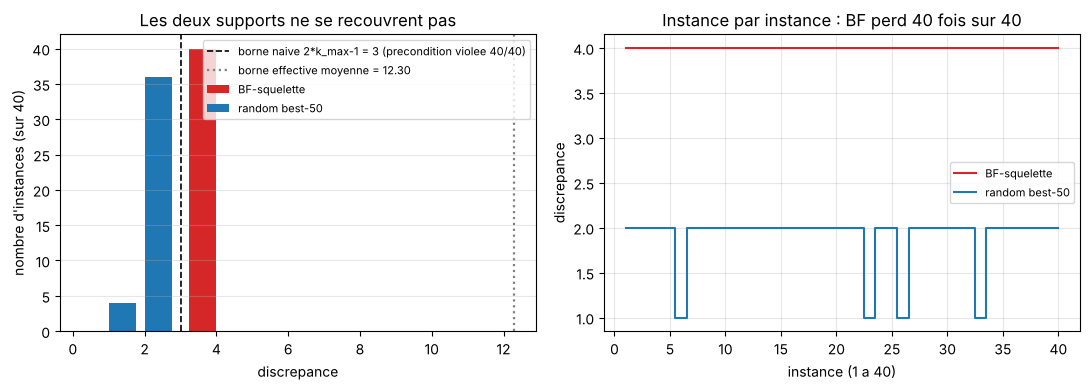

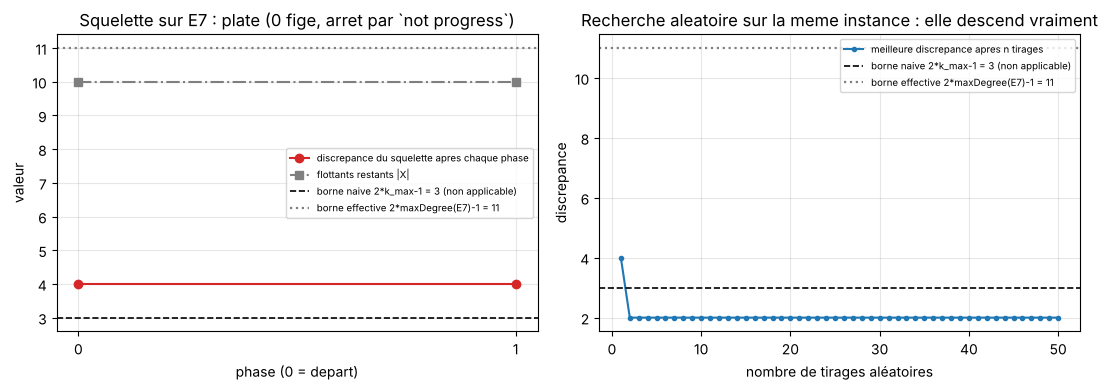

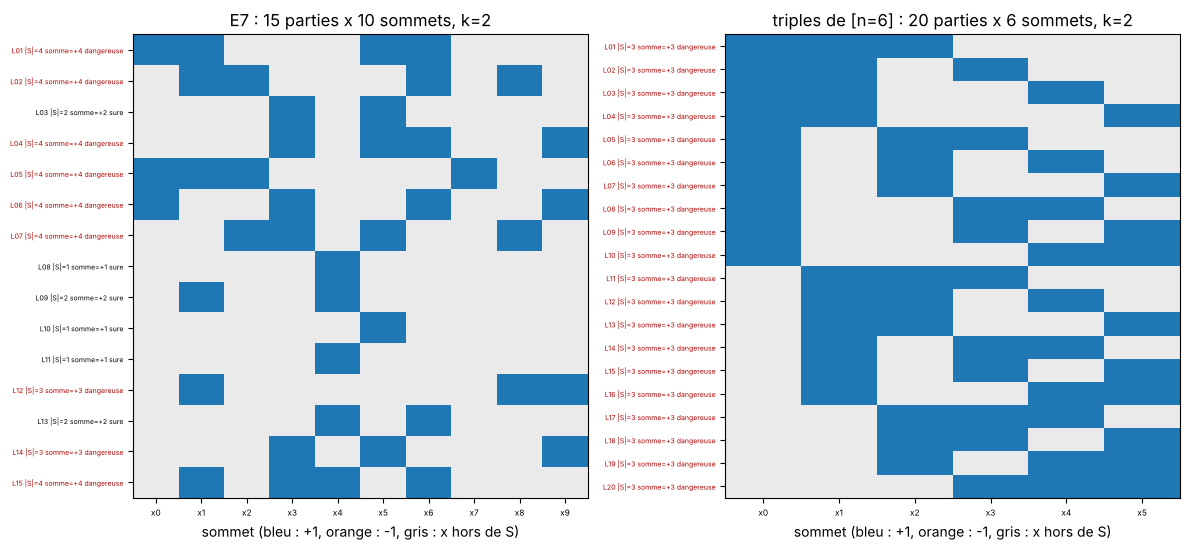

Lectures : la coloration finale de E7 ne contient que [1] ; les sommes par ligne valent donc les cardinalites |S| elles-memes.
  E7         : disc = 4 = max |S| = 4
  triples_6  : disc = 3 = max |S| = 3


In [3]:
# === VISUALISATION — trois figures sur les mesures des cellules 2 et 4 ===
#
# Toutes les grandeurs tracées ici sont MESURÉES dans cette cellule : aucune n'est recopiée de
# la prose. Le squelette de Beck-Fiala est rejoué phase par phase sur une instance choisie, et la
# recherche aléatoire est rejouée avec la même graine que la cellule 4 (le dernier point de la
# courbe doit donc valoir `rnd_discs[0]` — c'est vérifié juste après le calcul).
#
#   figure 1 : distribution des discrépances BF-squelette contre random best-50, et les bornes
#   figure 2 : trace de convergence — phases du squelette, tirages de la recherche aléatoire
#   figure 3 : matrice de signes de la coloration finale (une ligne = une partie de F)

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap


def discrepance_arrondie(F, c):
    """Discrépance de la coloration courante, arrondie par signe (`c[x] >= 0` donne `+1`)."""
    return discrepancy_int(F, {x: (1 if c[x] >= 0 else -1) for x in c})


def beck_fiala_trace(F, k, max_iter=100, seed=7):
    """Rejoue la boucle de `beck_fiala` en conservant la trace, phase par phase.

    Renvoie `(disc, flottants, figes)` : discrépance de la coloration arrondie, nombre de
    flottants restants et nombre de sommets figés, avant la première phase puis après chacune.
    La graine est fixée, car `rounding_pass` tire son pas dans `random.uniform`.
    """
    random.seed(seed)
    universe = set().union(*F) if F else set()
    if not universe:
        return [], [], []
    c = {x: 0.0 for x in universe}
    X = set(universe)
    disc, flottants, figes = [discrepance_arrondie(F, c)], [len(X)], [0]
    for _ in range(max_iter):
        danger = [S for S in F if len(S & X) > k]
        if not danger:
            break
        c, X, _, progress = rounding_pass(F, k, c, X, danger)
        disc.append(discrepance_arrondie(F, c))
        flottants.append(len(X))
        figes.append(len(universe) - len(X))
        if not progress or not X:
            break
    return disc, flottants, figes


def courbe_recherche_aleatoire(F, n_sommets, n_restarts=50, seed=2000):
    """Meilleure discrépance atteinte après `n` tirages aléatoires (`n` de 1 à 50)."""
    rng = random.Random(seed)
    meilleur, courbe = None, []
    for _ in range(n_restarts):
        d = discrepancy_int(F, random_coloring(n_sommets, rng))
        meilleur = d if meilleur is None else min(meilleur, d)
        courbe.append(meilleur)
    return courbe


# --- Instance E7 : la première instance de la cellule 4 (`seed=1000`), rejouée pour la trace. ---
E7 = random_hypergraph(10, 15, 2, seed=1000)
E7_MAXDEG = max_degree(E7)
e7_disc, e7_flottants, e7_figes = beck_fiala_trace(E7, 2)
e7_courbe = courbe_recherche_aleatoire(E7, 10)
e7_color = beck_fiala(E7, 2)[0]
E7_SOMMETS = sorted(set().union(*E7))

print(f"Instance E7 (n=10, m=15, k_max=2, seed=1000) : |F|={len(E7)}, maxDegree={E7_MAXDEG}")
print(f"  trace du squelette  : disc={e7_disc}  flottants={e7_flottants}  figes={e7_figes}")
print(f"  recherche aleatoire : meilleure disc apres 50 tirages = {e7_courbe[-1]}")
print(f"  coherence cellule 4 : e7_courbe[-1] == rnd_discs[0] -> {e7_courbe[-1] == rnd_discs[0]}")
print(f"  coloration finale   : {sorted(set(e7_color.values()))} (sommets a +1 : "
      f"{sum(1 for x in e7_color if e7_color[x] == 1)} / {len(e7_color)})")

# --- Figure 1 : distribution des discrépances, BF-squelette contre random best-50. ---
fig1, (f1a, f1b) = plt.subplots(1, 2, figsize=(11.0, 4.0))
valeurs = sorted(set(bf_discs) | set(rnd_discs))
demi = 0.38
f1a.bar([v - demi for v in valeurs], [bf_discs.count(v) for v in valeurs], 2 * demi,
        color="#d62728", label="BF-squelette")
f1a.bar([v + demi for v in valeurs], [rnd_discs.count(v) for v in valeurs], 2 * demi,
        color="#1f77b4", label="random best-50")
f1a.axvline(2 * kmax - 1, color="black", linestyle="--", linewidth=1.2,
            label=f"borne naive 2*k_max-1 = {2 * kmax - 1} (precondition violee 40/40)")
f1a.axvline(statistics.mean(max_degrees) * 2 - 1, color="gray", linestyle=":", linewidth=1.6,
            label=f"borne effective moyenne = "
                  f"{statistics.mean(2 * d - 1 for d in max_degrees):.2f}")
f1a.set_xlabel("discrepance")
f1a.set_ylabel("nombre d'instances (sur 40)")
f1a.set_title("Les deux supports ne se recouvrent pas")
f1a.legend(fontsize=8)
f1a.grid(axis="y", alpha=0.3)

f1b.step(range(1, len(bf_discs) + 1), bf_discs, where="mid", color="#d62728",
         label="BF-squelette")
f1b.step(range(1, len(rnd_discs) + 1), rnd_discs, where="mid", color="#1f77b4",
         label="random best-50")
f1b.set_xlabel("instance (1 a 40)")
f1b.set_ylabel("discrepance")
f1b.set_title("Instance par instance : BF perd 40 fois sur 40")
f1b.legend(fontsize=8)
f1b.grid(alpha=0.3)
fig1.tight_layout()
plt.show()

# --- Figure 2 : trace de convergence, squelette contre recherche aléatoire. ---
fig2, (f2a, f2b) = plt.subplots(1, 2, figsize=(11.0, 4.0))
phases = list(range(len(e7_disc)))
f2a.step(phases, e7_disc, where="post", marker="o", color="#d62728",
         label="discrepance du squelette apres chaque phase")
f2a.step(phases, e7_flottants, where="post", marker="s", color="#7f7f7f", linestyle="-.",
         label="flottants restants |X|")
f2a.axhline(2 * kmax - 1, color="black", linestyle="--", linewidth=1.2,
            label=f"borne naive 2*k_max-1 = {2 * kmax - 1} (non applicable)")
f2a.axhline(2 * E7_MAXDEG - 1, color="gray", linestyle=":", linewidth=1.6,
            label=f"borne effective 2*maxDegree(E7)-1 = {2 * E7_MAXDEG - 1}")
f2a.set_xlabel("phase (0 = depart)")
f2a.set_xticks(phases)
f2a.set_ylabel("valeur")
f2a.set_title(f"Squelette sur E7 : plate ({e7_figes[-1]} fige, arret par `not progress`)")
f2a.legend(fontsize=7, loc="center right")
f2a.grid(alpha=0.3)

f2b.plot(range(1, len(e7_courbe) + 1), e7_courbe, marker=".", color="#1f77b4",
         label="meilleure discrepance apres n tirages")
f2b.axhline(2 * kmax - 1, color="black", linestyle="--", linewidth=1.2,
            label=f"borne naive 2*k_max-1 = {2 * kmax - 1} (non applicable)")
f2b.axhline(2 * E7_MAXDEG - 1, color="gray", linestyle=":", linewidth=1.6,
            label=f"borne effective 2*maxDegree(E7)-1 = {2 * E7_MAXDEG - 1}")
f2b.set_xlabel("nombre de tirages aléatoires")
f2b.set_ylabel("discrepance")
f2b.set_title("Recherche aleatoire sur la meme instance : elle descend vraiment")
f2b.legend(fontsize=7, loc="upper right")
f2b.grid(alpha=0.3)
fig2.tight_layout()
plt.show()

# --- Figure 3 : matrice de signes de la coloration finale. ---
CMAP = ListedColormap(["#ff7f0e", "#eaeaea", "#1f77b4"])
NORM = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3)


def dessine_matrice(ax, F, coloring, sommets, titre, k):
    """Une ligne par partie de `F`, une colonne par sommet ; la case vaut `c[x]` si `x in S`."""
    m = [[coloring[x] if x in S else 0 for x in sommets] for S in F]
    ax.imshow(m, cmap=CMAP, norm=NORM, aspect="auto")
    etiquettes = []
    for i, S in enumerate(F):
        danger = "dangereuse" if len(S) > k else "sure"
        etiquettes.append(f"L{i + 1:02d} |S|={len(S)} somme={sum(m[i]):+d} {danger}")
    ax.set_yticks(range(len(F)))
    ax.set_yticklabels(etiquettes, fontsize=5)
    for tick, S in zip(ax.get_yticklabels(), F):
        tick.set_color("#b00000" if len(S) > k else "black")
    ax.set_xticks(range(len(sommets)))
    ax.set_xticklabels([f"x{x}" for x in sommets], fontsize=6)
    ax.set_title(titre)
    ax.set_xlabel("sommet (bleu : +1, orange : -1, gris : x hors de S)")


fig3, (f3a, f3b) = plt.subplots(1, 2, figsize=(12.0, 5.6))
dessine_matrice(f3a, E7, e7_color, E7_SOMMETS,
                f"E7 : {len(E7)} parties x {len(E7_SOMMETS)} sommets, k={kmax}", kmax)
dessine_matrice(f3b, triples_6, coloring6, list(range(n6)),
                f"triples de [n={n6}] : {len(triples_6)} parties x {n6} sommets, k={k6}", k6)
fig3.tight_layout()
plt.show()

print(f"Lectures : la coloration finale de E7 ne contient que {sorted(set(e7_color.values()))} ; "
      f"les sommes par ligne valent donc les cardinalites |S| elles-memes.")
print(f"  E7         : disc = {discrepancy_int(E7, e7_color)} = max |S| = {max(len(S) for S in E7)}")
print(f"  triples_6  : disc = {discrepancy_int(triples_6, coloring6)} = max |S| = "
      f"{max(len(S) for S in triples_6)}")

### Figure 1 — distribution des discrépances, BF-squelette contre random best-50 (cellule 6)

Le volet gauche superpose les deux distributions sur la même abscisse `disc` et y porte les deux bornes ; le volet droit les sépare instance par instance, ce qu'un histogramme de distribution dégénérée ne peut pas montrer.

**Ce que la figure mesure.** Le squelette rend **4 sur les 40 instances** — une distribution dégénérée à un seul point. La recherche aléatoire best-of-50 rend **1** (4 instances) ou **2** (36 instances) : `mean = 1.90` contre `4.00`, rapport 2.105. Les deux supports **ne se recouvrent pas** : `BF min = 4 > random max = 2` sur **40/40**, ce que la marche du volet droit montre d'un coup d'œil.

**Ce que la figure ajoute à la cellule 5.** La borne naïve `2*k_max - 1 = 3` tombe **entre** les deux supports. La borne **effective** `2*maxDegree(F) - 1` vaut en moyenne **12.30** (minimum 7, maximum 17) : le squelette est donc loin **sous** la borne qu'il pourrait légitimement revendiquer — il ne perd pas contre la borne, il perd contre du hasard.

**Pourquoi `disc = 4` exactement, et jamais autre chose.** Les deux figures suivantes répondent ; la troisième donne la raison mécanique.

### Figure 2 — trace de convergence : le squelette ne bouge pas (cellule 6)

La figure porte sur l'instance **E7** — la première de la cellule 4 : `n=10`, `m=15`, `k_max=2`, `seed=1000`, `maxDegree = 6`. Elle devait montrer un « profil en escalier » ; elle montre un **plateau**.

**Volet gauche.** La discrépance vaut `4` avant la phase et `4` après (`disc = [4, 4]`) ; surtout, le nombre de flottants restants vaut `[10, 10]` — **aucun sommet n'est figé** (`figes = [0, 0]`). La boucle s'arrête après **une** phase, par la branche `not progress` : le mécanisme est mesuré et expliqué à l'item 3 de la cellule 5.

**Volet droit.** Sur la même instance, la meilleure des `n` colorations aléatoires décroît de `4` à `2` en 50 tirages. C'est cette comparaison — et non la borne du théorème — qui produit le rapport 2.105 de la cellule 4.

**Ce que la trace change pour l'Exercice 1.** La décroissance stricte attendue de `bf_loop` suppose qu'au moins un flottant soit figé par phase ; avec la direction triviale, ce n'est jamais le cas. L'Exercice 1 n'est donc pas une amélioration cosmétique, c'est la condition pour que la boucle avance d'un seul pas.

### Figure 3 — matrice de signes de la coloration finale (cellule 6)

Chaque ligne est une partie `S` de `F`, chaque colonne un sommet, et la case vaut `c[x]` si `x in S` (gris clair sinon). Les étiquettes **rouges** de l'axe vertical marquent les lignes dangereuses au sens de l'algorithme (`|S| > k`) ; chacune porte aussi la somme de sa ligne.

**Ce que la figure montre.** La coloration finale de **E7** ne contient que `+1` : les 10 sommets sont à `+1`, aucun à `-1`. La matrice est donc monochrome là où elle est remplie, et la somme de chaque ligne vaut sa cardinalité — l'explication directe du `4` constant des deux figures précédentes. Le volet droit donne le même constat sur la famille `triples_6` de la cellule 2 : les 20 triplets somment à `+3`.

**Ce que la matrice ajoute.** Sur un hypergraphe non trivial, la valeur atteinte est celle d'une coloration **constante** : le squelette recopie le signe par défaut (`c[x] >= 0` donne `+1`) sur tous les sommets et n'équilibre rien. Une coloration qui équilibre vraiment rendrait des sommes proches de zéro, avec des signes **mêlés** dans chaque ligne — ce que la matrice ne contient nulle part.

## Exercice 1 : une direction noyau pour la phase de rond

Implémentez `random_kernel_vector(F, k, X, danger)` — sa spécification complète, trois propriétés à vérifier, est donnée en tête de la cellule suivante — puis contrôlez que la direction retournée est nulle hors de `X` et annule la somme sur chaque ligne dangereuse de `F`.

In [4]:
# === EXERCICE 1 - Implementer la sélection de direction `v` comme un vrai vecteur noyau ===
#
# Enonce :
#   La phase ci-dessus choisit une direction heuristique (un seul flottant pivot). Le lean
#   `exists_phase` (BeckFiala.lean l.80) exige un vecteur `v` non nul dans le noyau de la
#   matrice lignes-dangereuses x flottants (`Q^X -> Q^D` non injectif). Ecrire une fonction
#   `random_kernel_vector(F, k, X, danger)` qui renvoie un vecteur `v` verifiant :
#       (1) `v` est nul sur les éléments hors de `X` (les flottants uniquement) ;
#       (2) pour chaque ligne dangeseuse `S in danger`, `sum_{x in S & X} v[x] = 0` ;
#       (3) au moins une composante de `v` est non nulle.
#
#   Indication : former la matrice `M : |danger| x |X|` a coefficients dans `{0, 1}` (1 ssi
#   l'élément `x in X` appartient a la ligne `S`) ; un vecteur noyau est orthogonal aux lignes
#   de `M`. Une approche simple : prendre un vecteur aléatoire `r in [-1, 1]^X` et projeter
#   orthogonalement `v = r - M^+ . M . r` (pseudo-inverse), ou orthonormaliser une base du
#   noyau par Gram-Schmidt (pas besoin de numpy).
#
#   Une fois implemente, remplacer la direction heuristique dans `rounding_pass` et observer
#   l'effet sur la convergence et la discrepance en cellule 4.

def random_kernel_vector(F: Sequence[FrozenSet[int]], k: int, X: set,
                         danger: Sequence[FrozenSet[int]]) -> Dict[int, float] | None:
    """Renvoie un vecteur `v` non nul, nul hors de X, de somme nulle sur chaque ligne dangeseuse.

    Implementation a completer par l'etudiant - retourner `None` tant que non implemente.
    """
    # TODO etudiant - cf. enonce ci-dessus (orthogonalisation sur les lignes dangeseuses).
    print("Exercice 1 a completer - retourner None tant que non implemente.")
    return None

In [5]:
# === EXERCICE 2 - Implementer un oracle de discretisation exacte par CP-SAT (Z3) ===
#
# Enonce :
#   Le theoreme `beck_fiala_classic` est constructif via l'algorithme ci-dessus, mais rien
#   n'empeche de verifier aussi via un solveur exact (CP-SAT / Z3) que la borne `2k-1` est
#   bien infranchissable pour une famille donnee :
#
#       Variables : `c[x]` dans `{-1, +1}` pour chaque `x in universe`.
#       Contraintes : `-(2k-1) <= sum_{x in S} c[x] <= (2k-1)` pour chaque `S in F`.
#
#   Si `Z3` est disponible sur la machine (`importlib.util.find_spec('z3')` reussit), utiliser
#   `z3.Optimize()` ou `z3.Solver()` avec `z3.Int` pour les variables, et chercher une
#   coloration qui minimise la **plus grande** valeur absolue de somme sur `F`.
#
#   Si `Z3` n'est pas disponible, retourner `None` et noter pourquoi (on n'invente
#   pas une reponse). Voici la signature a completer :

import importlib.util


def z3_min_discrepancy(F: Sequence[FrozenSet[int]]) -> int | None:
    """Renvoie la discrepance minimale pour `F` par Z3 CP-SAT, ou `None` si Z3 absent.

    Implementation a completer - retourner `None` tant que non implemente.
    """
    if importlib.util.find_spec('z3') is None:
        return None
    # TODO etudiant - cf. enonce ci-dessus (variables `c[x] in {-1, +1}`, contraintes de borne
    # `-(2k-1) <= sum_{x in S} c[x] <= (2k-1)` pour chaque S, optimisation de `max |sum|`).
    print("Exercice 2 a completer - Z3 present, implementation a completer.")
    return None


# Test rapide : detecter Z3 par `importlib.util.find_spec` (pas `try/except ImportError`).
z3_present = importlib.util.find_spec('z3') is not None
result = z3_min_discrepancy(triples_6)
if z3_present and result is None:
    print("Z3 present sur cette machine, exercice 2 non implemente (a completer).")
elif not z3_present:
    print("Z3 absent sur cette machine (None honnete).")
else:
    print(f"Z3 résultat : {result}")

Exercice 2 a completer - Z3 present, implementation a completer.
Z3 present sur cette machine, exercice 2 non implemente (a completer).


In [6]:
# === EXERCICE 3 - Le pont formel : citer verbatim les noms Lean et tracer la frontiere ===
#
# Énoncé :
#   Le tableau ci-dessous distingue ce qui est **certifié sur `main`**
#   de ce qui ne l'est pas : aucune conjecture n'y est présentée comme un résultat.
#   Pour chaque énoncé Lean, le nom verbatim du `.lean` et le statut sont
#   relevés dans le dépôt.

TABLE = [
    # (nom_verbatim, statut, source, cas_d_usage)
    ('Discrepancy.IsColoring',                       'PROUVE',          'Basic.lean l.44',     'def dans la documentation du squelette'),
    ('Discrepancy.discrepancy',                      'PROUVE',          'Basic.lean l.50',     'def utilisee par `discrepancy_int` cellule 2'),
    ('Discrepancy.degree',                           'PROUVE',          'Basic.lean l.56',     'def utilisee par `max_degree` cellule 2'),
    ('Discrepancy.maxDegree',                        'PROUVE',          'Basic.lean l.61',     'def utilisee par `max_degree` cellule 2'),
    ('Discrepancy.BeckFialaConjecture',              'PROP_NOMMEE',     'Basic.lean l.104',    'conjecture O(sqrt(k)) - non prouvee sur main'),
    ('Discrepancy.BeckFialaClassic',                 'PROP_NOMMEE',     'Basic.lean l.118',    'cible de `beck_fiala_classic` - non prouvee directement, mais assemblee via b1-b4'),
    ('Discrepancy.exists_dangerous_kernel_vec',      'PROUVE',          'Kernel.lean l.107',   'employe BeckFiala.lean l.96 - ferme Exercice 1'),
    ('Discrepancy.BFInv',                            'PROUVE',          'BeckFiala.lean l.45', 'invariant structurel de la phase'),
    ('Discrepancy.exists_phase',                     'PROUVE sur main', 'BeckFiala.lean l.80', 'graine de la boucle `bf_loop`'),
    ('Discrepancy.exists_coloring_of_no_danger',     'PROUVE sur main', 'BeckFiala.lean l.231','applique b1-b4 a chaque phase'),
    ('Discrepancy.bf_loop',                          'PROUVE sur main', 'BeckFiala.lean l.250','boucle principale - termine par decroissance stricte de |X|'),
    ('Discrepancy.beck_fiala_classic',               'PROUVE sur main', 'BeckFiala.lean l.283','THEOREME PRINCIPAL - `disc <= 2k-1`'),
]
print(f"Tableau verbatim (statuts relevés dans le dépôt) : {len(TABLE)} entree(s).")
for nom, statut, src, usage in TABLE:
    print(f"  - {nom:50s} {statut:18s} {src:25s} {usage}")
print()
print("Frontiere epistemique tracee :")
print("  - Le theoreme `beck_fiala_classic` est PROUVE sur main (Lake build SUCCESS).")
print("  - Les conjectures `BeckFialaConjecture` (O(sqrt k)) et `KomlosConjecture` (O(1))")
print("    sont PROP_NOMMEES (def... : Prop sans preuve) - voir FORMAL_STATUS.md.")
print("  - Le squelette BF Python n'est pas une implémentation de référence : il perd")
print("    face a random best-50, et c'est le signal pedagogique recherche.")

Tableau verbatim (statuts relevés dans le dépôt) : 12 entree(s).
  - Discrepancy.IsColoring                             PROUVE             Basic.lean l.44           def dans la documentation du squelette
  - Discrepancy.discrepancy                            PROUVE             Basic.lean l.50           def utilisee par `discrepancy_int` cellule 2
  - Discrepancy.degree                                 PROUVE             Basic.lean l.56           def utilisee par `max_degree` cellule 2
  - Discrepancy.maxDegree                              PROUVE             Basic.lean l.61           def utilisee par `max_degree` cellule 2
  - Discrepancy.BeckFialaConjecture                    PROP_NOMMEE        Basic.lean l.104          conjecture O(sqrt(k)) - non prouvee sur main
  - Discrepancy.BeckFialaClassic                       PROP_NOMMEE        Basic.lean l.118          cible de `beck_fiala_classic` - non prouvee directement, mais assemblee via b1-b4
  - Discrepancy.exists_dangerous_kernel_vec 